<a href="https://colab.research.google.com/github/tanush-2008/IIITH-Collab-Notebooks/blob/main/AIML_Module_3_Lab_3_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regression Lab: Regularization, SVM Regression and Logistic Regression

## Part A: Ridge and Lasso Regularization

In [ ]:
import numpy as np
import pandas as pd
import random
import math
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.style.use('ggplot')
from matplotlib.pylab import rcParams
rcParams['figure.figsize'] = 10, 8

from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
import numpy as np

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
import sklearn.metrics as metrics

## Motivation behind regularization

Most, if not all real world data is noisy, i.e. there are outliers in the data which throw the model off during training. Let's look at a noisy sine wave as an example. We'll try to fit polynomials of various degree to the curve.

In [ ]:
np.random.seed(10)

x = np.array([i*np.pi/180 for i in range(60,300,4)]).reshape((-1,1))
y = np.sin(x) + np.random.normal(0,0.15,x.shape)

In [ ]:
def poly_regression(x, y, deg, show=True):

    poly = PolynomialFeatures(degree=deg)
    x_ = poly.fit_transform(x)

    m1 = LinearRegression()
    m1.fit(x_, y)
    y_pred = m1.predict(x_)

    if show:
        plt.figure(figsize=(10, 6))
        plt.plot(x, y_pred, color="red")
        plt.scatter(x, y, color="blue")
        plt.title(f"Polynomial Regression (degree={deg})")
        plt.legend(["Predicted polynomial", "Actual data"])
        plt.show()

        print("Coefficients obtained:")
        print(m1.coef_)

    return y_pred

In [ ]:
import matplotlib.pyplot as plt

For now, let's not think about how we obtain these coefficients. We'll look into how they are obtained in a later module.

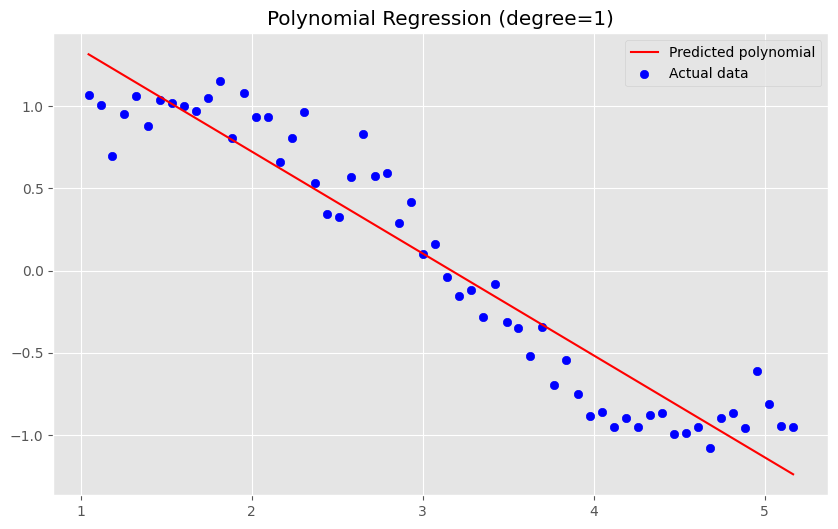

Coefficients obtained:
[[ 0.         -0.61957457]]


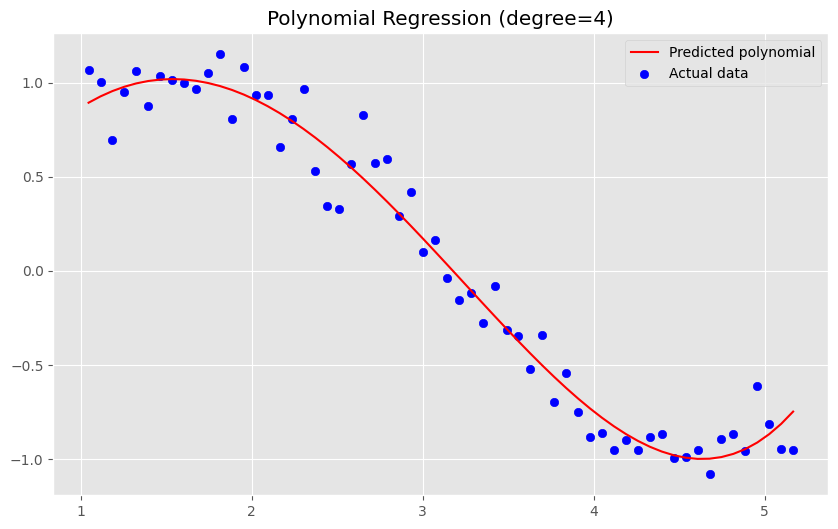

Coefficients obtained:
[[ 0.          1.68692165 -0.53175186 -0.03567846  0.01391921]]


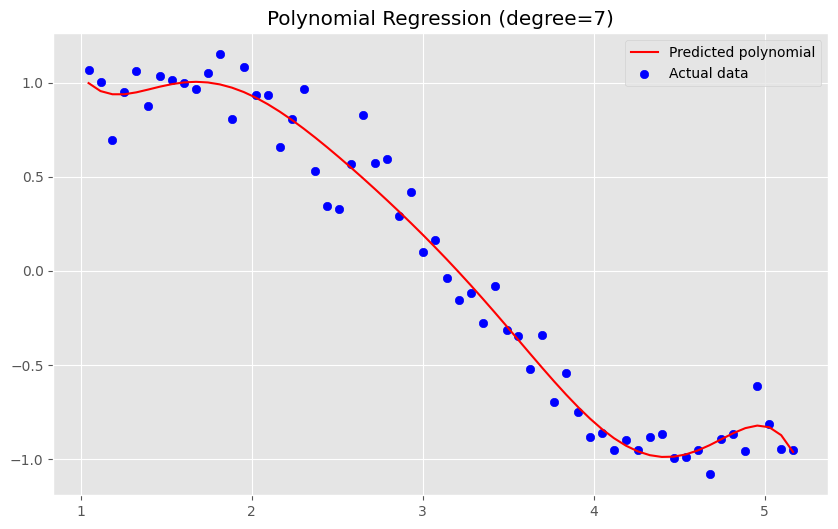

Coefficients obtained:
[[ 0.00000000e+00 -5.59523300e+01  6.89561793e+01 -4.46319058e+01
   1.65148424e+01 -3.52813549e+00  4.04509832e-01 -1.92268762e-02]]


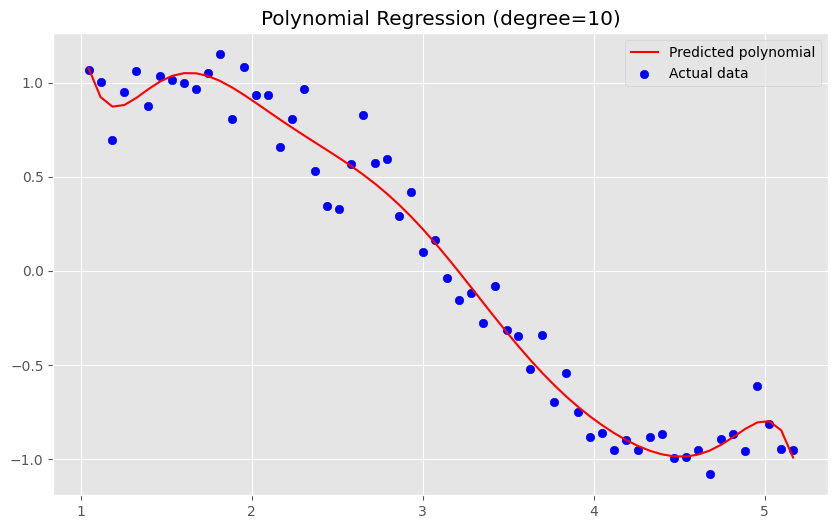

Coefficients obtained:
[[ 0.00000000e+00 -4.86125436e+02  7.26133286e+02 -5.95881204e+02
   2.93255837e+02 -8.74564585e+01  1.45461928e+01 -8.06079171e-01
  -1.38203819e-01  2.62230806e-02 -1.32095456e-03]]


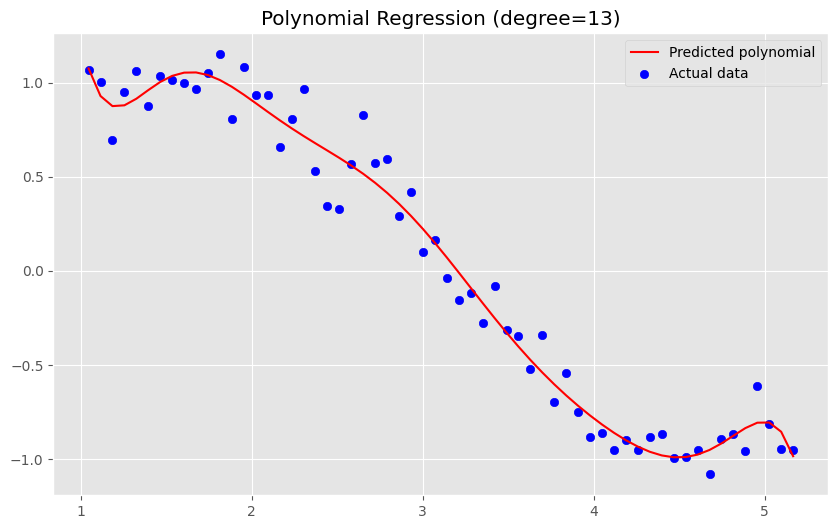

Coefficients obtained:
[[ 0.00000000e+00 -1.20901775e+02  5.00736786e+01  7.27324131e+01
  -5.64600592e+01 -4.13474096e+01  7.88655828e+01 -5.21574464e+01
   1.99430568e+01 -4.87943643e+00  7.78676260e-01 -7.87346339e-02
   4.59351098e-03 -1.18076316e-04]]


In [ ]:
for deg in range(1, 14, 3):
    y_pred = poly_regression(x, y, deg)

The higher degree polynomials **overfit** the training data, by trying to capture noise in it. Though the model may do well on this set, if we try to fit the learnt curve to another noisy sine wave, it would result in a lower accuracy. Luckily, there's a way around this.

**Q:** What trend do you observe with respect to the coefficient values as degree grows?

\

**A:** The magnitudes of the coefficients go up drastically with degree!

\

Now, why does that happen? Intuitively, we can think about what the polynomial is trying to fit here. In the above example, the polynomial is trying to fit to a noisy sine wave. To approximate the large oscillations we see, the coefficients need to have large magnitudes. We can also see that this only happens with higher degree polynomials, since lower degree polynomials cannot even approximate these oscillations.

## Ridge Regression

Ridge regression works by adding a term to the loss function which is proportional to the sum of the squared coefficients of the model.

$L_r = \sum_{i=1}^{N} (y - y_p) ^2 + \alpha |w|^2$,

where $\sum_{i=1}^{N} (y - y_p) ^2$ is the typical mean-squared error loss and $\alpha |w|^2$ is the regularization term, $w$ being the coefficient of the term. We can see that it penalizes the squared value of the coefficients.

In [ ]:
def ridge_regression(x,y,deg,alpha):

  poly = PolynomialFeatures(degree=deg)
  x_ = poly.fit_transform(x)

  r = Ridge(alpha)
  r.fit(x_,y)

  y_pred_ridge = r.predict(x_)

  plt.title("Ridge Regressed polynomial deg={}, alpha={}".format(deg,alpha))
  plt.scatter(x,y,color="blue")
  plt.plot(x,y_pred_ridge,color="red")
  plt.legend(["actual data","predicted data"])
  plt.show()

  print("\n Coefficients obtained\n")
  print(r.coef_)
  print("\n")

## Lasso Regression

Lasso regression is similar to ridge regression, except it penalizes the absolute value of the weights.

$L_l = \sum_{i=1}^{N} (y - y_p) ^2 + \alpha |w|$

In [ ]:
def lasso_regression(x,y,deg,alpha):

  poly = PolynomialFeatures(degree=deg)
  x_ = poly.fit_transform(x)

  l = Lasso(alpha)
  l.fit(x_,y)

  y_pred_lasso = l.predict(x_)

  plt.title("Lasso Regressed polynomial deg={}, alpha={}".format(deg,alpha))
  plt.scatter(x,y,color="blue")
  plt.show()

  print("\n Coefficients obtained\n")
  print(l.coef_)
  print("\n")

### Feature selection

Sometimes, data may contain features that are not relevant to the model; they do not contribute to the model's predictions. Naturally, we would want to get rid of such features in our data. **Feature selection** is a process by which we understand which features are actually relevant to the model and remove the unrelated features from our data.

The advantage of lasso regularization over ridge regularization is that it does a better job of feature selection. In ridge regression, the coefficient can approach zero, but never truly reaches zero. Hence, the model cannot perform feature selection.

In lasso regression, since we are penalizing the absolute value of the coefficient, the feature can have a zero coefficient, which is the same as feature selection. In the above example, we can clearly see the feature selection process in action, with higher degree polynomials have zero-valued coefficients for some of the terms.

## Applying regularization to the crime dataset

In [ ]:
src = 'http://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data'
crime = pd.read_csv(src, header=None, na_values=['?'])

crime.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [ ]:
def lin_regression(x,y,show=True):

  # learning the coefficient and intercept

  x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2)

  m1 = LinearRegression()
  m1.fit(x_train,y_train)

  y_pred = m1.predict(x_test)
  metrics.mean_squared_error(y_pred,y_test)

  # plotting data and predictions

  if show:

    print("The coefficients are: \n {} \n\n The intercept is: {}\n".format(m1.coef_,m1.intercept_))
    print("The RMSE for linear regression is: {}".format(math.sqrt(metrics.mean_squared_error(y_pred,y_test))))

In [ ]:
# Remove identifier columns and target column
x_crime = crime.drop(columns=[0, 1, 2, 3, 4, 127])

# Target variable
y_crime = crime[127]

# Convert remaining features to numeric
x_crime = x_crime.apply(pd.to_numeric, errors='coerce')

# Replace missing values with column median
x_crime = x_crime.fillna(x_crime.median())

In [ ]:
lin_regression(x_crime, y_crime)

The coefficients are: 
 [ 2.62189350e-01 -5.74943620e-02  1.21451878e-01 -1.44551700e-01
 -5.06896299e-02  1.15923540e-01  3.35495886e-02 -3.13848308e-01
 -2.24658298e-02 -4.50828117e-02 -4.09478957e-01  5.94607551e-02
 -3.11598556e-01 -1.40804858e-01  6.26475282e-02 -1.81274800e-01
  2.31072665e-01 -3.42828277e-02 -8.79025353e-02  4.38660978e-01
  3.01148935e-02 -3.30709240e-01 -3.49813567e-02 -1.84772883e-02
  2.70178344e-02  3.92498383e-02  2.94942077e-02  2.64060211e-01
 -2.02351410e-01 -9.05322518e-02  6.90550353e-02  8.54866519e-02
  2.53339123e-02  2.55158589e-01 -4.53810570e-02 -2.89906751e-02
  5.85006272e-02  1.32330637e-01  5.21282014e-01  2.33891388e-01
  1.37919933e-01 -6.30317933e-01 -5.47275833e-03 -2.07115500e-01
 -1.75017245e-01 -6.12872181e-02  2.65001821e-02  1.86846290e-02
 -1.56463221e-01 -1.98844110e-01  1.06191780e-01 -2.00140452e-01
  1.14060810e-03  4.03836620e-02 -1.22870746e-03 -4.93634233e-02
 -3.79321543e-02 -8.28760780e-02  9.97784708e-02  1.23178426e-02
 

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x_crime,y_crime,test_size=0.3)

In [ ]:
l = Lasso(alpha=0.002)
l.fit(x_train,y_train)
y_pred_lasso = l.predict(x_test)

print("The coefficients are: \n {}".format(l.coef_))
print("The RMSE for lasso regression is: {}".format(math.sqrt(metrics.mean_squared_error(y_pred_lasso,y_test))))

The coefficients are: 
 [ 0.         -0.          0.07548453 -0.13340209  0.          0.
 -0.         -0.         -0.          0.          0.          0.03222945
 -0.         -0.          0.         -0.          0.          0.
 -0.         -0.          0.          0.         -0.         -0.
  0.          0.          0.          0.          0.          0.
  0.         -0.          0.         -0.         -0.         -0.
 -0.         -0.          0.11422596 -0.          0.          0.
  0.         -0.         -0.2570344  -0.         -0.         -0.
 -0.02721596  0.          0.18208815  0.          0.          0.
  0.          0.          0.          0.          0.          0.
 -0.          0.          0.          0.          0.         -0.
  0.         -0.          0.09973808  0.         -0.          0.06699947
 -0.03870963 -0.          0.02424044 -0.          0.          0.
  0.          0.          0.          0.         -0.          0.
  0.          0.          0.          0.         -

## Part B: SVM Regression

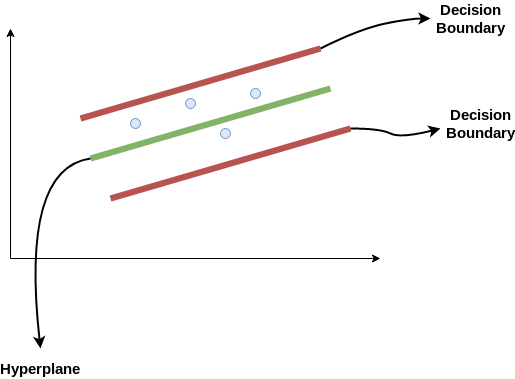

We know that the SVM algorithm works by finding a dividing hyperplane between the two classes in some feature space. How do we apply that concept to the task of regression?

The key insight is that we can define a parameter $ϵ$ which defines a "tube" around the hyperplane (in the diagram, the green line is the hyperplane and the two red lines determine the tube around it. Each red line is $ϵ$ units away from the hyperplane. We then define a "slack" term $ξ$ which measures the distance between the decision boundary (red line) and outliers (points outside the tube). In the code below, the variable `C` represents the slack term.

We can thus define an optimization problem of minimizing the $ξ$ value while trying to fit as many points in the tube as possible.

In [ ]:
import numpy as np

np.random.seed(10)

X = np.linspace(-5, 5, 100).reshape(-1, 1)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, 100)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR

model1 = LinearRegression()
model1.fit(X, y)

epsilon = 0.1
model2 = SVR(kernel='rbf', C=100, epsilon=epsilon)
model2.fit(X, y)

SVR(C=100)

In [ ]:
x_range = np.linspace(X.min(), X.max(), 100)

y_lr = model1.predict(x_range.reshape(-1, 1))
y_svr = model2.predict(x_range.reshape(-1, 1))

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

fig = px.scatter(
    x=X.flatten(),
    y=y,
    opacity=0.8,
    color_discrete_sequence=['black']
)

fig.add_trace(go.Scatter(
    x=x_range, y=y_lr,
    name='Linear Regression',
    line=dict(color='limegreen')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr,
    name='Support Vector Regression',
    line=dict(color='red')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr + epsilon,
    name='+epsilon',
    line=dict(color='red', dash='dot')
))

fig.add_trace(go.Scatter(
    x=x_range, y=y_svr - epsilon,
    name='-epsilon',
    line=dict(color='red', dash='dot')
))

fig.update_layout(
    plot_bgcolor='white',
    title='Linear Regression vs Support Vector Regression',
    xaxis_title='X',
    yaxis_title='Y'
)

fig.update_xaxes(
    showgrid=True, gridwidth=1, gridcolor='lightgrey',
    zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey',
    showline=True, linewidth=1, linecolor='black'
)

fig.update_yaxes(
    showgrid=True, gridwidth=1, gridcolor='lightgrey',
    zeroline=True, zerolinewidth=1, zerolinecolor='lightgrey',
    showline=True, linewidth=1, linecolor='black'
)

fig.update_traces(marker=dict(size=3))

fig.show()

## Part C: Logistic Regression

Just as we have linear and polynomial regression for predicting numerical values, we have another type of regression for predicting class labels of data, namely **logistic regression**.

The reason its called logistic regression is because it makes use of the logistic function to generate output values. The logistic function is defined as:

$g(z) = \frac{1}{1 + e^{-z}}$

\

The reason we use the logistic function is because its range is bounded between 0 and 1. Anything else comes to mind when talking about values between 0 and 1? Probabilities! And we saw in lab 2 how deeply related probability and classification are.

<img src="https://drive.google.com/uc?export=view&id=1db86qd4W_4erTMC9no5P4ylWze6c2j7V" width="500" height="350" align="middle"/>

## Why use logistic function? Why not use linear regression?

Let's see why we can't use linear regression for classification tasks with the help of an example.

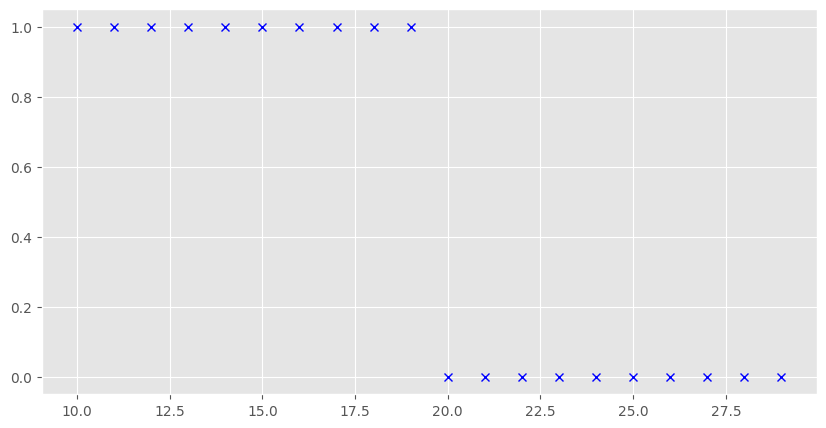

In [ ]:
x = np.array([i for i in range(10,30)])
y = np.concatenate([np.ones(10), np.zeros(10)])

fig = plt.figure(figsize=(10,5))
_ = plt.plot(x, y, 'xb')

Suppose we have some product, and we collected data on the relationship between the age of a customer, and whether they purchased the item or not. Customers aged between 10 and 19 made the purchase (purchased=1), whereas those customers above the age of 19 did not (purchased=0).

\

Now, let's try and fit linear regression and logistic regression models to this data, and test it.

In [ ]:
def linear_regression(x,y):

  lin_regression = LinearRegression()
  lin_regression.fit(pd.DataFrame(x), y)

  lin_y_pred_1 = lin_regression.predict(pd.DataFrame(x))

  line_point_5 = x * 0 + .5

  fig = plt.figure(figsize=(10,5))
  xlabel = 'Age'
  ylabel = 'Purchased'
  plt.xlabel(xlabel)

  plt.legend(["Data Points","Linear Regression Model","Decision Boundary"])
  plt.show()

  return lin_regression

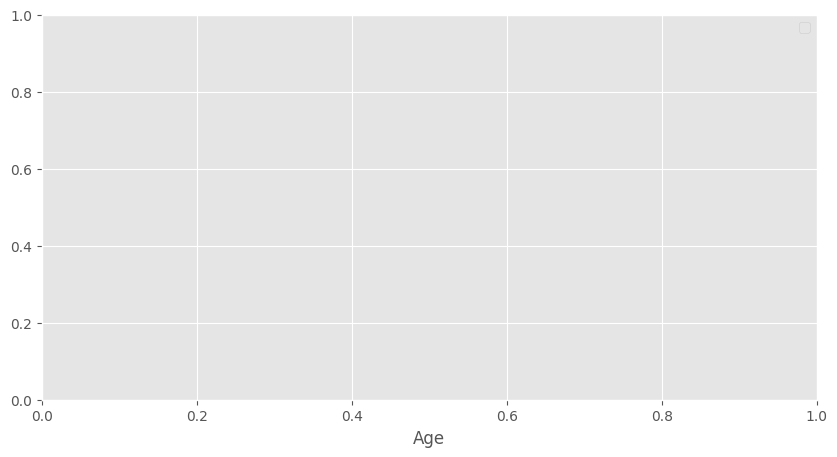

In [ ]:
lin_regression = linear_regression(x,y)

The green line is called the decision boundary, which is basically the line that divides the two classes on the cartesian plane.

In [ ]:
test_x = np.array([i for i in range(10,35,5)])
test_y_pred = lin_regression.predict(pd.DataFrame(test_x))
test_y_pred

array([ 1.21428571,  0.83834586,  0.46240602,  0.08646617, -0.28947368])

Since linear regression predictions are not probabilities, values greater than 0.5 are considered to belong to positive purchase class.

In [ ]:
def logistic_regression(x,y):

    log_regression = LogisticRegression()

    log_regression.fit(pd.DataFrame(x), y)

    log_y_pred_1 = log_regression.predict(pd.DataFrame(x))

    xlabel = 'Age'
    ylabel = 'Purchased'

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    plt.grid(color='k', linestyle=':', linewidth=1)

    plt.plot(x, y, 'xb')
    plt.plot(x, log_y_pred_1, '-r')

    plt.legend(["Data Points","Logistic Regression Model"])
    plt.show()

    return log_regression

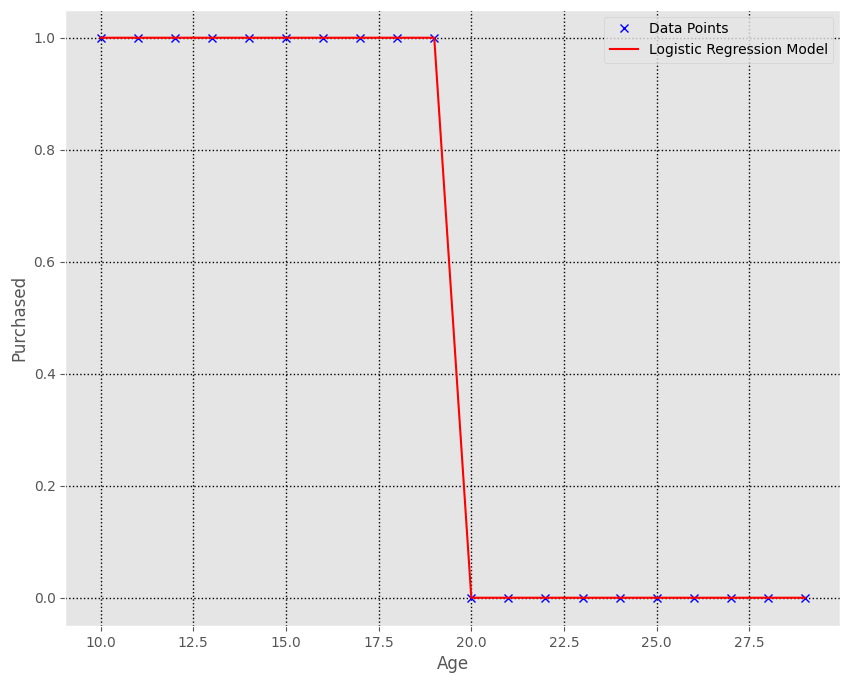

In [ ]:
log_regression = logistic_regression(x,y)

**Q:** What do you observe from the two graphs? Hint: think in terms of the decision boundary....

**A:** According to the linear regression model, any age greater than 19 would belong to class 0 (no purchase), and any age less than or equal to 19 would belong to class 1 (purchase made). The logistic regression curve follows the same trend. We can think of the age 19 as a turning point of sorts.

Now, say we've collected more data the next day, and add the new data to the existing data we had from day 1. We find that customers aged between 60 and 70 did not make a purchase, which is aligned with our earlier data as well.

In [ ]:
x = np.append(x, np.array([i for i in range(60,70)]))
y = np.append(y, np.zeros(10))

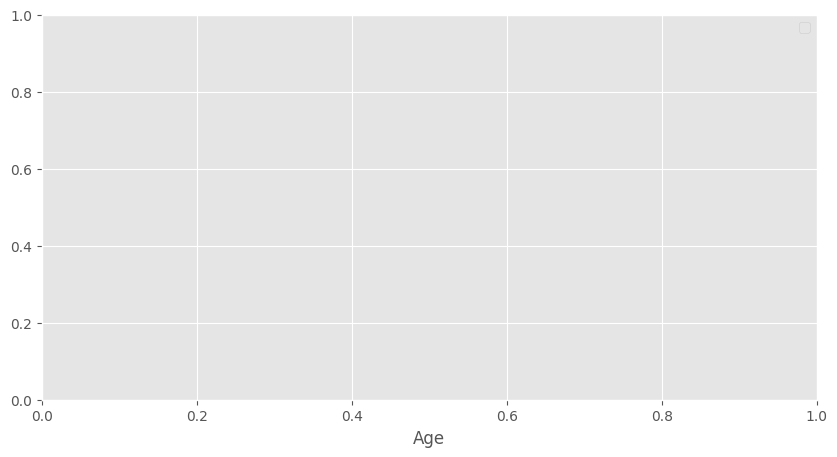

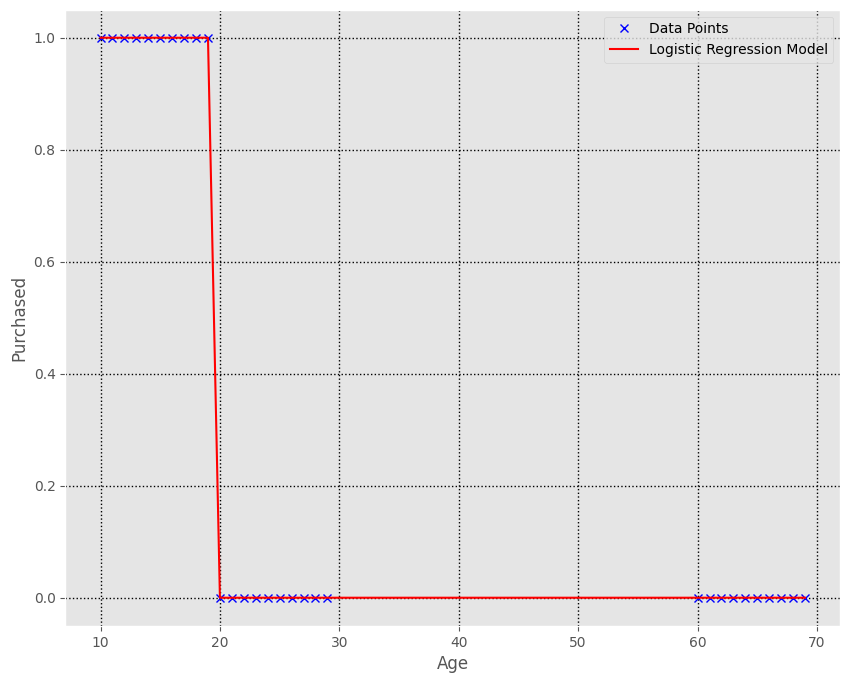

In [ ]:
lin_regression = linear_regression(x,y)
log_regression = logistic_regression(x,y)

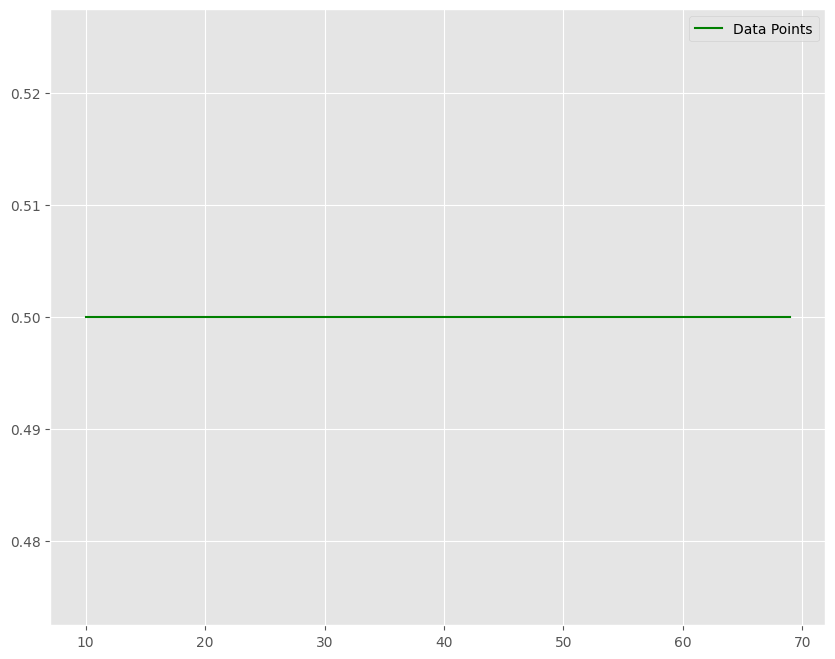

In [ ]:
test_x = np.array([i for i in range(18,26)])

test_y_pred_lin = lin_regression.predict(pd.DataFrame(test_x))

line_point_5 = x * 0 + 0.5

plt.plot(x, line_point_5, '-g')
plt.legend(["Data Points", "Logistic Regression Model", "Decision Boundary"])
plt.show()


We can now see where linear regression fails. The model tries to fit as many points as it can. By doing so, the turning point which was earlier 19 has now increased to 23, which is clearly wrong for the values 20, 21 and 22, which can be seen from the predictions on the test data.

\

On the other hand, the logistic regression model predicts the classes correctly, and perfectly models the relationship between the data.

What we can conclude from these observations are that a probabilistic model is required for classification problems. Lab 2 covered the intuition behind MLE, cross-entropy and classification, and so now you should be able to appreaciate the motivation behind logistic regression.

## Applying logistic regression to MNIST digit Dataset

Let's see logistic regression in action with the MNIST digits dataset.

In [ ]:
import seaborn as sns

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    digits.data,
    digits.target,
    test_size=0.2,
    random_state=0
)

log_reg = LogisticRegression()
log_reg = log_reg.fit(x_train, y_train)

In [ ]:
# Accuracy

acc = log_reg.score(x_test,y_test)
print("Accuracy obtained on test set: {}".format(round(acc*100,3)))

Accuracy obtained on test set: 96.667


In [ ]:
y_pred = log_reg.predict(x_test)

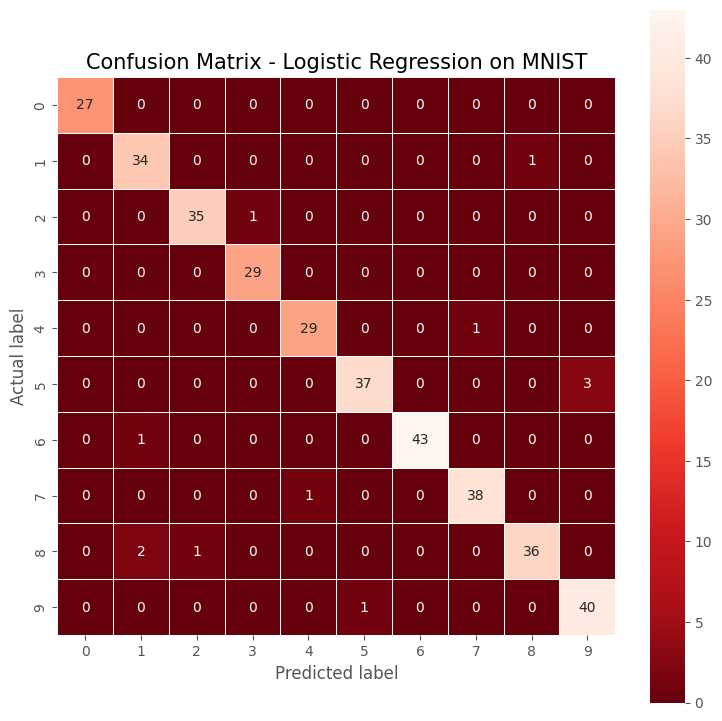

In [ ]:
cm = metrics.confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9,9))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Reds_r')

plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title("Confusion Matrix - Logistic Regression on MNIST", size=15)
plt.show()

## Exercises

### Regularization:
1. Play with the values of alpha in both regularization techniques, and try to predict the outcomes.
2. Try the regularizations on different datasets to see the effect in various ways.

### SVM regression:
1. Play around with the value of `epsilon` and plot the different regression curves obtained.
2. Change `C` and analyze the different plots obtained.

### Logistic regression:
1. Run logistic regression on different datasets and assess the results.

## Student work — solutions to all five exercises

The faculty-provided notes, demonstrations, and code cells above are preserved. The following **additional student cells** address every exercise: (A1) regularization strength, (A2) regularization on another dataset, (B1) SVR `epsilon`, (B2) SVR `C`, and (C1) logistic regression on other datasets. Experiments use fixed seeds, train/test splits, and explicit metrics so outcomes are reproducible and comparable. No external CSV upload is required for these additional experiments.

In [ ]:
# Student exercise setup — independent of faculty variables overwritten earlier.
from sklearn.datasets import load_diabetes, load_iris, load_wine, load_breast_cancer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

student_seed = 42

def student_rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

print('Student experiment setup complete; random_state =', student_seed)

Student experiment setup complete; random_state = 42


### Exercise A1 — Vary `alpha` in Ridge and Lasso

**Prediction:** Larger `alpha` penalizes model coefficients more strongly. Ridge usually shrinks coefficients continuously; Lasso can set some coefficients **exactly to zero**. Excessively large `alpha` can underfit. We keep polynomial degree, random split, and preprocessing fixed to isolate the effect of regularization strength.

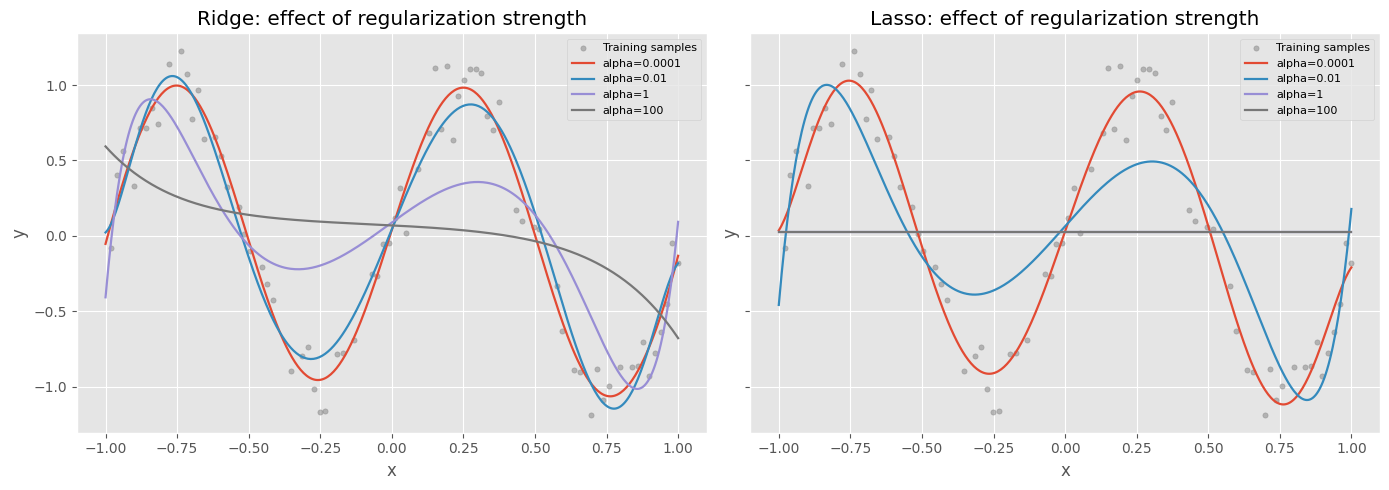

Model    alpha  Test RMSE  L2 coefficient norm  Nonzero coefficients
Ridge   0.0001     0.1784              30.0548                     9
Ridge   0.0010     0.1911              17.9595                     9
Ridge   0.0100     0.2215              12.0051                     9
Ridge   0.1000     0.3502               5.7538                     9
Ridge   1.0000     0.4414               2.2391                     9
Ridge  10.0000     0.5694               0.5506                     9
Ridge 100.0000     0.6271               0.1373                     9
Lasso   0.0001     0.1876              20.5122                     6
Lasso   0.0010     0.2225              13.1072                     6
Lasso   0.0100     0.3904               3.5976                     6
Lasso   0.1000     0.6079               0.2814                     1
Lasso   1.0000     0.6752               0.0000                     0
Lasso  10.0000     0.6752               0.0000                     0
Lasso 100.0000     0.6752         

In [ ]:
# Noisy nonlinear regression: train and test sets are kept fixed for every alpha.
student_rng = np.random.default_rng(student_seed)
student_x = np.linspace(-1.0, 1.0, 100).reshape(-1, 1)
student_y = np.sin(2 * np.pi * student_x[:, 0]) + student_rng.normal(0, 0.20, 100)
student_xtr, student_xte, student_ytr, student_yte = train_test_split(
    student_x, student_y, test_size=0.25, random_state=student_seed
)
student_xgrid = np.linspace(-1, 1, 400).reshape(-1, 1)
student_alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
student_reg_rows = []

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (label, estimator) in zip(axes, [('Ridge', Ridge), ('Lasso', Lasso)]):
    ax.scatter(student_xtr, student_ytr, s=14, color='gray', alpha=0.5, label='Training samples')
    for alpha in student_alphas:
        reg = estimator(alpha=alpha, max_iter=300000) if label == 'Lasso' else estimator(alpha=alpha)
        model = make_pipeline(PolynomialFeatures(degree=9, include_bias=False), StandardScaler(), reg)
        model.fit(student_xtr, student_ytr)
        test_predictions = model.predict(student_xte)
        coeff = model.steps[-1][1].coef_
        student_reg_rows.append({
            'Model': label, 'alpha': alpha,
            'Test RMSE': student_rmse(student_yte, test_predictions),
            'L2 coefficient norm': float(np.linalg.norm(coeff)),
            'Nonzero coefficients': int(np.sum(np.abs(coeff) > 1e-7))
        })
        if alpha in [0.0001, 0.01, 1, 100]:
            ax.plot(student_xgrid, model.predict(student_xgrid), lw=1.6, label=f'alpha={alpha:g}')
    ax.set(title=f'{label}: effect of regularization strength', xlabel='x', ylabel='y')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
student_reg_results = pd.DataFrame(student_reg_rows)
print(student_reg_results.round(4).to_string(index=False))
print('\nBest test RMSE by technique:')
print(student_reg_results.loc[student_reg_results.groupby('Model')['Test RMSE'].idxmin()].round(4).to_string(index=False))

**Student answer (A1):** Coefficient norms and fitted curves show how the penalty influences complexity. Lasso's reported nonzero-coefficient count highlights feature selection; Ridge tends to retain all polynomial terms. The printed held-out RMSE identifies the best `alpha` **for this particular split**; neither the smallest nor largest penalty is automatically best. Alpha values must be compared using the *same preprocessing and test examples*.

### Exercise A2 — Apply both regularizers to a different dataset

Use scikit-learn's **Diabetes** regression dataset (442 samples, 10 features). Compare unregularized linear regression, Ridge, and Lasso on the same held-out test set. Standardize features using *training data only* inside each pipeline to avoid leakage.

            Model  alpha  Test RMSE  Test R2  Nonzero coefficients
Linear (baseline)    NaN     53.370    0.485                    10
            Ridge   0.01     53.369    0.485                    10
            Ridge   0.10     53.362    0.485                    10
            Ridge   1.00     53.318    0.486                    10
            Ridge  10.00     53.204    0.488                    10
            Ridge 100.00     53.080    0.490                    10
            Lasso   0.01     53.359    0.485                    10
            Lasso   0.10     53.282    0.487                     9
            Lasso   1.00     52.773    0.496                     9
            Lasso  10.00     53.713    0.478                     4
            Lasso 100.00     74.881   -0.014                     0

Best candidate on this held-out set:
Model                       Lasso
alpha                         1.0
Test RMSE               52.772955
Test R2                  0.496358
Nonzero coefficients  

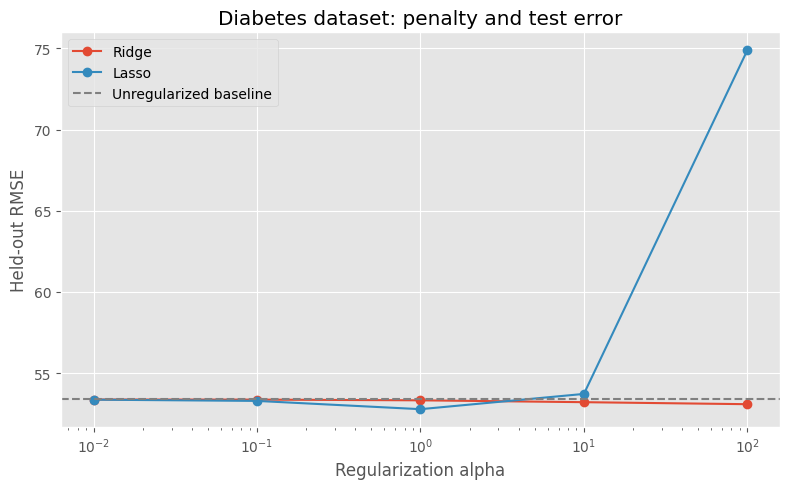

In [ ]:
student_diabetes = load_diabetes()
student_dxtr, student_dxte, student_dytr, student_dyte = train_test_split(
    student_diabetes.data, student_diabetes.target,
    test_size=0.25, random_state=student_seed
)
student_base = make_pipeline(StandardScaler(), LinearRegression())
student_base.fit(student_dxtr, student_dytr)
student_diabetes_rows = [{
    'Model': 'Linear (baseline)', 'alpha': np.nan,
    'Test RMSE': student_rmse(student_dyte, student_base.predict(student_dxte)),
    'Test R2': r2_score(student_dyte, student_base.predict(student_dxte)),
    'Nonzero coefficients': 10
}]

for name, estimator in [('Ridge', Ridge), ('Lasso', Lasso)]:
    for alpha in [0.01, 0.1, 1, 10, 100]:
        reg = estimator(alpha=alpha, max_iter=300000) if name == 'Lasso' else estimator(alpha=alpha)
        pipe = make_pipeline(StandardScaler(), reg)
        pipe.fit(student_dxtr, student_dytr)
        preds = pipe.predict(student_dxte)
        student_diabetes_rows.append({
            'Model': name, 'alpha': alpha,
            'Test RMSE': student_rmse(student_dyte, preds),
            'Test R2': r2_score(student_dyte, preds),
            'Nonzero coefficients': int(np.count_nonzero(np.abs(pipe.steps[-1][1].coef_) > 1e-7))
        })
student_diabetes_results = pd.DataFrame(student_diabetes_rows)
print(student_diabetes_results.round(3).to_string(index=False))
print('\nBest candidate on this held-out set:')
print(student_diabetes_results.loc[student_diabetes_results['Test RMSE'].idxmin()].round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 5))
for label in ['Ridge', 'Lasso']:
    sub = student_diabetes_results.loc[student_diabetes_results['Model'] == label]
    ax.plot(sub['alpha'], sub['Test RMSE'], marker='o', label=label)
ax.axhline(student_diabetes_results.iloc[0]['Test RMSE'], color='gray', ls='--', label='Unregularized baseline')
ax.set(xscale='log', xlabel='Regularization alpha', ylabel='Held-out RMSE', title='Diabetes dataset: penalty and test error')
ax.legend()
plt.tight_layout()
plt.show()

**Student answer (A2):** Both methods can regularize the same ten input features. Ridge is useful when coefficients should be **shrunk but retained**; Lasso can produce a sparse set of coefficients. The best held-out RMSE is dataset- and split-dependent. These results compare fixed candidates on one test split; for formal model selection, tune `alpha` by cross-validation *within the training set* and evaluate the selected model once on untouched test data.

### Exercise B1 — Vary SVR `epsilon` and compare regression curves

The `epsilon` parameter specifies the width of the no-penalty tube around the SVR prediction. With `C` and the kernel held constant, larger `epsilon` generally tolerates larger residuals and often reduces the number of support vectors. It does **not** equal the slack variable.

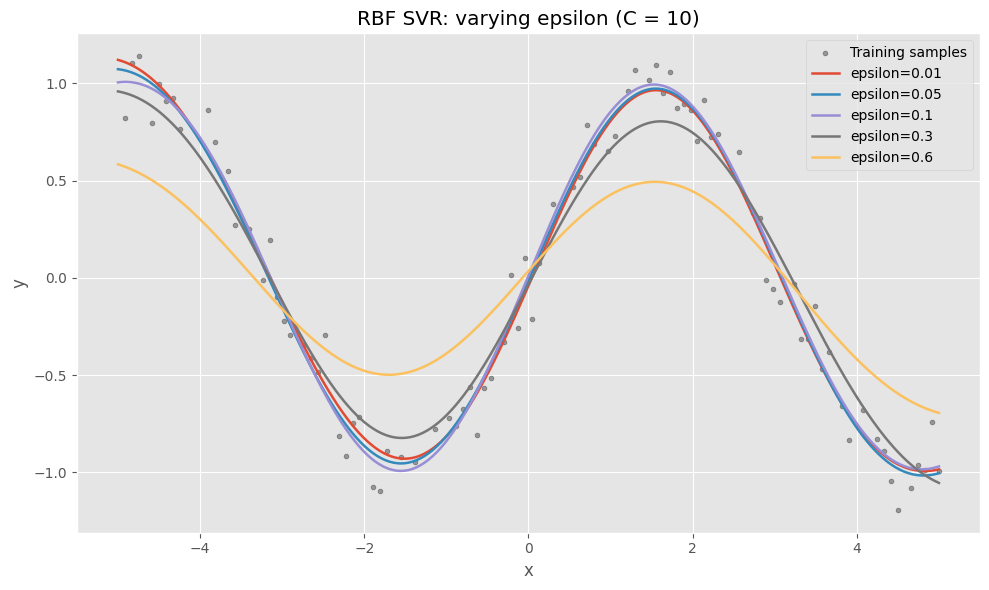

 epsilon  C  Test RMSE  Support vectors
    0.01 10     0.1304               82
    0.05 10     0.1227               59
    0.10 10     0.1177               42
    0.30 10     0.1851                6
    0.60 10     0.4031                5


In [ ]:
student_svr_rng = np.random.default_rng(student_seed)
student_svr_x = np.linspace(-5, 5, 120).reshape(-1, 1)
student_svr_y = np.sin(student_svr_x[:, 0]) + student_svr_rng.normal(0, 0.15, 120)
student_sxtr, student_sxte, student_sytr, student_syte = train_test_split(
    student_svr_x, student_svr_y, test_size=0.25, random_state=student_seed
)
student_svr_grid = np.linspace(-5, 5, 400).reshape(-1, 1)
student_epsilons = [0.01, 0.05, 0.1, 0.3, 0.6]
student_epsilon_rows = []
plt.figure(figsize=(10, 6))
plt.scatter(student_sxtr, student_sytr, color='black', s=12, alpha=0.35, label='Training samples')
for epsilon in student_epsilons:
    m = SVR(kernel='rbf', C=10, epsilon=epsilon, gamma='scale')
    m.fit(student_sxtr, student_sytr)
    student_epsilon_rows.append({
        'epsilon': epsilon, 'C': 10,
        'Test RMSE': student_rmse(student_syte, m.predict(student_sxte)),
        'Support vectors': int(len(m.support_))
    })
    plt.plot(student_svr_grid, m.predict(student_svr_grid), lw=1.8, label=f'epsilon={epsilon:g}')
plt.title('RBF SVR: varying epsilon (C = 10)')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.tight_layout(); plt.show()
student_epsilon_results = pd.DataFrame(student_epsilon_rows)
print(student_epsilon_results.round(4).to_string(index=False))

**Student answer (B1):** Small `epsilon` asks SVR to fit a narrow tolerance band and may need more support vectors; larger `epsilon` permits greater deviations and often yields a simpler solution. Compare the printed **test RMSE** rather than assuming a wider or narrower tube always predicts better. The curves differ even though all other model settings and data are identical.

### Exercise B2 — Vary SVR `C` and analyze the plots

`C` controls the **penalty for errors outside the epsilon tube**, not the slack variable itself. A larger `C` penalizes those violations more heavily; a smaller `C` allows a smoother, more strongly regularized fit. Keep `epsilon = 0.1`, the RBF kernel, and the train/test split unchanged.

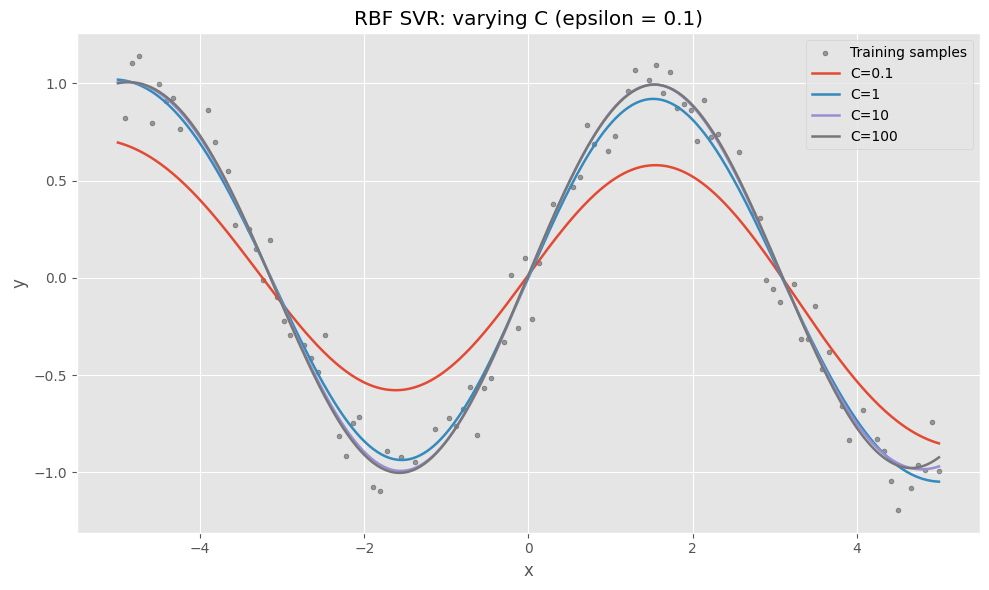

    C  epsilon  Train RMSE  Test RMSE  Support vectors
  0.1      0.1      0.2853     0.3295               81
  1.0      0.1      0.1216     0.1298               40
 10.0      0.1      0.1172     0.1177               42
100.0      0.1      0.1174     0.1138               41


In [ ]:
student_C_values = [0.1, 1, 10, 100]
student_C_rows = []
plt.figure(figsize=(10, 6))
plt.scatter(student_sxtr, student_sytr, color='black', s=12, alpha=0.35, label='Training samples')
for c_value in student_C_values:
    m = SVR(kernel='rbf', C=c_value, epsilon=0.1, gamma='scale')
    m.fit(student_sxtr, student_sytr)
    student_C_rows.append({
        'C': c_value, 'epsilon': 0.1,
        'Train RMSE': student_rmse(student_sytr, m.predict(student_sxtr)),
        'Test RMSE': student_rmse(student_syte, m.predict(student_sxte)),
        'Support vectors': int(len(m.support_))
    })
    plt.plot(student_svr_grid, m.predict(student_svr_grid), lw=1.8, label=f'C={c_value:g}')
plt.title('RBF SVR: varying C (epsilon = 0.1)')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.tight_layout(); plt.show()
student_C_results = pd.DataFrame(student_C_rows)
print(student_C_results.round(4).to_string(index=False))

**Student answer (B2):** Low `C` makes the fitted curve more tolerant of residual errors (more regularization); high `C` encourages closer agreement with training points (less regularization), which can eventually overfit noise. Changes in support-vector counts and test RMSE are not necessarily monotonic. The reported training/test errors show why **generalization**, not only training fit, matters when choosing `C`.

### Exercise C1 — Logistic regression on three other datasets

We use **Breast Cancer** (binary classification), **Iris** (3 classes), and **Wine** (3 classes). Each dataset gets a reproducible **stratified** train/test split and a standardization pipeline fitted only to its training fold. Report test accuracy, macro-F1, per-class precision/recall, and confusion matrices. These three examples extend the original Digits exercise.


Breast Cancer classification report (held-out test set):
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143


Iris classification report (held-out test set):
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.86      0.92      0.89        13
   virginica       0.92      0.85      0.88        13

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38


Wine classification report (held-out test set):
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00    

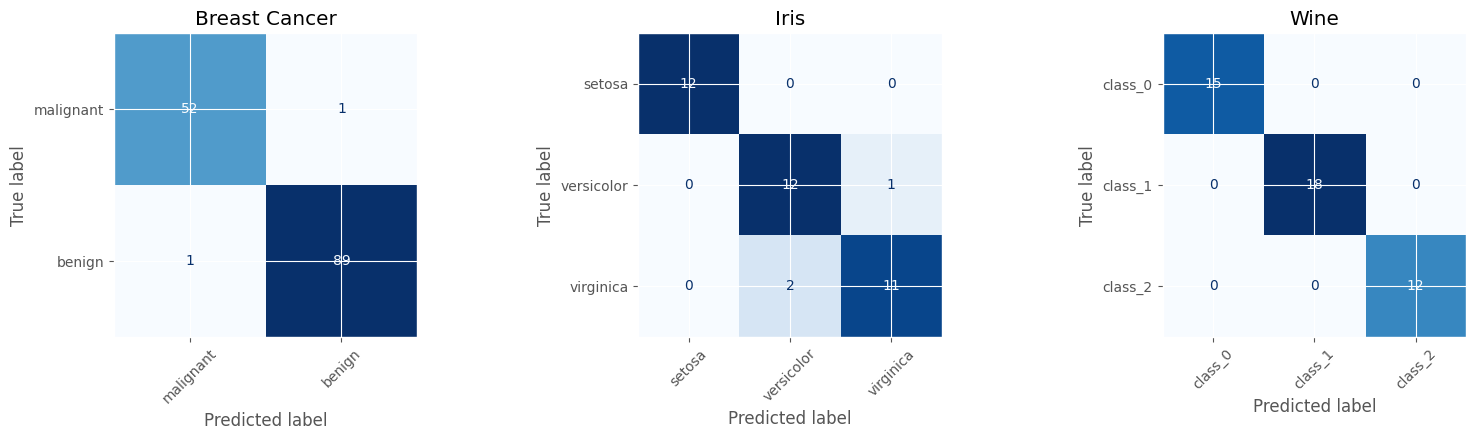


Logistic regression comparison:
      Dataset  Rows  Features  Classes  Test accuracy  Macro F1
Breast Cancer   569        30        2         0.9860     0.985
         Iris   150         4        3         0.9211     0.923
         Wine   178        13        3         1.0000     1.000


In [ ]:
student_classification_sets = [
    ('Breast Cancer', load_breast_cancer()),
    ('Iris', load_iris()),
    ('Wine', load_wine())
]
student_classification_rows = []
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, dataset) in zip(axs, student_classification_sets):
    Xtrain, Xtest, ytrain, ytest = train_test_split(
        dataset.data, dataset.target, test_size=0.25,
        random_state=student_seed, stratify=dataset.target
    )
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=student_seed))
    model.fit(Xtrain, ytrain)
    predictions = model.predict(Xtest)
    accuracy = accuracy_score(ytest, predictions)
    macro_f1 = f1_score(ytest, predictions, average='macro')
    student_classification_rows.append({
        'Dataset': name, 'Rows': len(dataset.data), 'Features': dataset.data.shape[1],
        'Classes': len(np.unique(dataset.target)), 'Test accuracy': accuracy,
        'Macro F1': macro_f1
    })
    print(f'\n{name} classification report (held-out test set):')
    print(classification_report(ytest, predictions, target_names=dataset.target_names, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        ytest, predictions, display_labels=dataset.target_names, ax=ax,
        colorbar=False, cmap='Blues', xticks_rotation=45
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()
student_classification_results = pd.DataFrame(student_classification_rows)
print('\nLogistic regression comparison:')
print(student_classification_results.round(4).to_string(index=False))

**Student answer (C1):** Logistic regression handles **both binary and multiclass** classification. The printed accuracy indicates the fraction of correct predictions, whereas **macro-F1** gives equal weight to each class, making it useful alongside accuracy when class sizes differ. Confusion matrices expose which classes were confused; the classification reports provide per-class precision and recall. All comparisons are on held-out samples, not training accuracy. Performance varies with dataset size, feature separability, and model assumptions; it should not be assumed identical across datasets.

### Final conclusions and reproducibility

1. **Ridge vs Lasso:** Both shrink coefficients; Lasso can select features by setting coefficients to zero. Tune `alpha` for the data rather than assuming stronger regularization is always better.
2. **SVR epsilon:** Defines the zero-penalty tolerance tube; typically trades sensitivity to training deviations against model sparsity.
3. **SVR C:** Sets the weight of penalties for tube violations; low values regularize more, and very large values can fit training noise.
4. **Logistic regression:** A probabilistic classifier effective for binary and multiclass problems; assess with accuracy, macro-F1, confusion matrices, and precision/recall.
5. **Method:** Fixed seeds, identical splits within comparisons, standardization fitted only on training folds, and separate held-out evaluation keep the experiments reproducible. These small comparisons are educational demonstrations rather than large-scale hyperparameter searches.